# OPERA DSWx-S1 - download and plot

This example notebook shows you how to download and plot OPERA DSWx-S1 radar surface water for a single lake
1. per acquisition (one row per Sentinel-1 scene)
2. monthly (one per-pixel mode composite per month)

and then inspect the result with the `DSWxDataset` class.

The product is visible only from 2024-08 onwards and has three limits worth knowing before reading a series:
* water bodies below ~3 ha / 200 m width are **not mapped** - such a polygon reads as "no water" by design
* there is **no snow/ice class**: a frozen basin is classified as *inundated vegetation*
* the vegetation classes are not the same quantity as Dynamic World's `flooded_vegetation`

### Imports

In [1]:
from water_timeseries.downloader import EarthEngineDownloader
from water_timeseries.dataset import DSWxDataset
import geopandas as gpd
import pandas as pd

In [2]:
%matplotlib inline


#### Loading vector dataset
* we are loading the provided lake polygon dataset
* the specific unique lake id is "id_geohash"
* DSWx-S1 is a 30 m product, so pick a lake comfortably above the ~3 ha minimum mapping unit

In [3]:
vector_path = "../tests/data/lake_polygons.parquet"
gdf = gpd.read_parquet(vector_path)
len(gdf)

118

In [4]:
gdf.head()

,label_id,id,Area_start_ha,Area_end_ha,NetChange_ha,NetChange_perc,GrossIncrease_ha,GrossIncrease_perc,GrossDecrease_ha,GrossDecrease_perc,...,id_geohash,river,source_file,staging_duplicated,area_vector_ha,area_ratio,num_holes,holes_per_ha,__index_level_0__,geometry
0,18644,18644,2.7009,2.8008,0.0999,3.698766,0.2043,7.564145,0.1044,3.727506,...,b7g6g1ny1mf7,0.0,lake_change_32603,False,2.684576,1.043293,0,0.0,61180,"POLYGON ((-164.03911 66.58432, -164.03912 66.5..."
1,18659,18659,1.0242,1.3743,0.3501,34.182775,0.5184,50.615114,0.1683,12.246235,...,b7g4yc12k4yj,0.0,lake_change_32603,False,1.341851,1.024182,0,0.0,61187,"POLYGON ((-164.23263 66.5835, -164.23264 66.58..."
2,18655,18655,4.4370,4.7583,0.3213,7.241379,0.7614,17.160244,0.4401,9.249102,...,b7g6c8gye56e,0.0,lake_change_32603,False,4.651507,1.022959,0,0.0,61188,"POLYGON ((-164.10951 66.58339, -164.10952 66.5..."
3,18667,18667,4.5747,4.4649,-0.1098,-2.400158,0.3312,7.239819,0.4410,9.877041,...,b7g4v0vsnux0,0.0,lake_change_32603,False,5.009950,0.913123,0,0.0,61192,"POLYGON ((-164.30774 66.58277, -164.30775 66.5..."
4,18670,18670,1.1349,1.0899,-0.0450,-3.965107,0.0234,2.061856,0.0684,6.275805,...,b7g6u8dbyu5m,0.0,lake_change_32603,False,1.252487,0.906117,0,0.0,61195,"POLYGON ((-163.97973 66.58044, -163.97974 66.5..."


#### Pick a lake
* `b7g4rf3n3x43` is a ~377 ha basin, well above the minimum mapping unit
* its polygon area is what the downloader normalises the no-data share against

In [5]:
lake_id = "b7g4rf3n3x43"
lake = gdf[gdf["id_geohash"] == lake_id].to_crs(6933)  # equal-area, the projection the downloader measures in
print(f"{lake_id}: {lake.geometry.area.iloc[0] / 1e4:.1f} ha")
lake[["id_geohash"]]

b7g4rf3n3x43: 377.6 ha


,id_geohash
78,b7g4rf3n3x43


#### Setup GEE account
* set project name to the EE_PROJECT environment variable (preferred) or pass it to the downloader

In [6]:
import os

os.environ.setdefault("EE_PROJECT", "your-gee-project")

'pdg-wg-workflow'

#### Setup logger (optional)
* here I am using loguru, you can also choose others

In [7]:
import loguru

logger = loguru.logger
logger.add("logfile_dswx.log", level=0)

1

#### Per-acquisition (daily) download
* one row per Sentinel-1 acquisition inside the date window - **not** a gap-filled daily series
* the date arguments are the same as for Dynamic World, so a `download_dw_daily` call is repointed by changing
  the method name: either `months` / `date_list` or a recurring `start_date` / `end_date` as `MM-DD`
* overlapping MGRS tiles are collapsed to one row per (polygon, date), never summed; a scene with no classified
  pixel is dropped ("no observation", not "zero water")
* one summer season for one lake takes ~1 minute
* returns an `xr.Dataset` with 2 coordinates (date, id_geohash) and 3 variables:
  `area_open_water`, `area_inundated_vegetation`, `area_not_water`

In [8]:
dl = EarthEngineDownloader(ee_project=os.environ["EE_PROJECT"], ee_auth=True, logger=logger)

ds_daily = dl.download_dswx_daily(
    vector_dataset=vector_path,
    name_attribute="id_geohash",
    id_list=[lake_id],
    years=[2025],
    start_date="06-01",   # 'MM-DD', inclusive, applied to every year
    end_date="09-30",     # 'MM-DD', inclusive
)

2026-11-19 18:15:26.535 +01:00 | INFO     | water_timeseries.downloader:_log_info:142 - Initializing EarthEngineDownloader with project: pdg-wg-workflow


2026-11-19 18:15:29.083 +01:00 | INFO     | water_timeseries.downloader:_log_info:142 - EarthEngineDownloader initialized successfully.


2026-11-19 18:15:29.085 +01:00 | INFO     | water_timeseries.downloader:_log_info:142 - Loading vector dataset from: ../tests/data/lake_polygons.parquet


2026-11-19 18:15:29.085 +01:00 | INFO     | water_timeseries.utils.io:load_vector_dataset:51 - Loading vector dataset from ../tests/data/lake_polygons.parquet


2026-11-19 18:15:29.089 +01:00 | INFO     | water_timeseries.downloader:_log_info:142 - Initial dataset has 118 features


2026-11-19 18:15:29.089 +01:00 | INFO     | water_timeseries.downloader:_log_info:142 - Applying ID filter: 1 IDs specified


... (12 outputs left out)


2026-11-19 18:15:35.508 +01:00 | INFO     | water_timeseries.downloader:_log_info:142 - Dropped 24 acquisition(s) with no classified pixels (no observation, not a zero water area)


2026-11-19 18:15:35.510 +01:00 | INFO     | water_timeseries.downloader:_log_info:142 - Collapsed 34 duplicate (polygon, date) row(s) from overlapping MGRS tiles, keeping the best-covered tile (tie-break: larger not-water area)


2026-11-19 18:15:35.510 +01:00 | INFO     | water_timeseries.downloader:_log_info:142 - Masked 0 acquisition(s) with more than 2.0% no-data (or 2 pixel(s) on polygons too small for a percentage)


2026-11-19 18:15:35.589 +01:00 | INFO     | water_timeseries.downloader:_log_info:142 - Download complete: 1 polygons, 41 acquisitions, 41 observations (per polygon: min 41, median 41, max 41)


In [9]:
ds_daily

<xarray.Dataset> Size: 1kB
Dimensions:                    (id_geohash: 1, date: 41)
Coordinates:
  * id_geohash                 (id_geohash) object 8B 'b7g4rf3n3x43'
  * date                       (date) datetime64[ns] 328B 2025-06-02 ... 2025...
Data variables:
    area_inundated_vegetation  (id_geohash, date) float64 328B 28.81 ... 42.49
    area_not_water             (id_geohash, date) float64 328B 343.9 ... 331.5
    area_open_water            (id_geohash, date) float64 328B 4.86 ... 3.51
Attributes:
    description:                  This dataset provides the surface water are...
    temporal_resolution:          per_acquisition
    product:                      OPERA DSWx-S1 (OPERA/DSWX/L3_V1/S1)
    accompanying vector dataset:  lake_polygons.parquet
    source:                       https://github.com/PermafrostDiscoveryGatew...
    author:                       Ingmar Nitze (Alfred Wegener Institute), To...
    contact:                      ingmar.nitze@awi.de
    season_window:                06-01..09-30
    max_nodata:                   0.02
    min_masked_pixels:            2.0
    n_acquisitions:               41

#### Monthly download
* one per-pixel mode composite of each month's acquisitions, the same statistic `download_dw_monthly` uses
* the date arguments are the monthly pair: `years` with `months`, or a `date_list` of `'YYYY-MM'`
* a month without a usable acquisition is **absent**, not zero
* all twelve months are downloaded here on purpose: the winter rows are the ice signal discussed at the end

In [10]:
ds_monthly = dl.download_dswx_monthly(
    vector_dataset=vector_path,
    name_attribute="id_geohash",
    id_list=[lake_id],
    years=[2025],
    months=list(range(1, 13)),
)

2026-11-19 18:15:35.616 +01:00 | INFO     | water_timeseries.downloader:_log_info:142 - Loading vector dataset from: ../tests/data/lake_polygons.parquet


2026-11-19 18:15:35.616 +01:00 | INFO     | water_timeseries.utils.io:load_vector_dataset:51 - Loading vector dataset from ../tests/data/lake_polygons.parquet


2026-11-19 18:15:35.616 +01:00 | INFO     | water_timeseries.downloader:_log_info:142 - Initial dataset has 118 features


2026-11-19 18:15:35.616 +01:00 | INFO     | water_timeseries.downloader:_log_info:142 - Applying ID filter: 1 IDs specified


2026-11-19 18:15:35.616 +01:00 | INFO     | water_timeseries.downloader:_log_info:142 - After ID filter: 1 features


2026-11-19 18:15:35.616 +01:00 | INFO     | water_timeseries.downloader:_log_info:142 - No spatial bbox filtering applied (using default global bounds)


... (5 outputs left out)

2026-11-19 18:15:35.632 +01:00 | INFO     | water_timeseries.downloader:_log_info:142 - Split 1 features into 1 chunks (chunk_size=1)


2026-11-19 18:15:35.632 +01:00 | INFO     | water_timeseries.downloader:_log_info:142 - Processing 1 chunks with 1 workers



2026-11-19 18:15:47.076 +01:00 | INFO     | water_timeseries.downloader:_log_info:142 - Masked 0 month(s) with more than 2.0% no-data (or 2 pixel(s) on polygons too small for a percentage)


2026-11-19 18:15:47.076 +01:00 | INFO     | water_timeseries.downloader:_log_info:142 - Download complete: 1 items, 12 months collected


In [11]:
ds_monthly

<xarray.Dataset> Size: 392B
Dimensions:                    (id_geohash: 1, date: 12)
Coordinates:
  * id_geohash                 (id_geohash) object 8B 'b7g4rf3n3x43'
  * date                       (date) datetime64[ns] 96B 2025-01-01 ... 2025-...
Data variables:
    area_inundated_vegetation  (id_geohash, date) float64 96B 259.8 ... 157.2
    area_not_water             (id_geohash, date) float64 96B 111.1 ... 204.1
    area_open_water            (id_geohash, date) float64 96B 6.629 ... 16.33
Attributes:
    description:                  This dataset provides the surface water are...
    temporal_resolution:          monthly
    product:                      OPERA DSWx-S1 (OPERA/DSWX/L3_V1/S1)
    accompanying vector dataset:  lake_polygons.parquet
    source:                       https://github.com/PermafrostDiscoveryGatew...
    author:                       Ingmar Nitze (Alfred Wegener Institute), To...
    contact:                      ingmar.nitze@awi.de
    monthly_composite:            mode
    max_nodata:                   0.02
    min_masked_pixels:            2.0

#### Save the downloads (optional)
* `.zarr` or `.nc`, decided by the extension - a cached file also saves Earth Engine calls when re-plotting

In [12]:
ds_daily.to_netcdf(f"dswx_daily_{lake_id}_2025.nc")
ds_monthly.to_netcdf(f"dswx_monthly_{lake_id}_2025.nc")

#### Load as DSWxDataset
* the class runs automatic checks while loading, it expects
  * 2 dimensions: "date", "id_geohash"
  * variables: `area_open_water`, `area_inundated_vegetation`, `area_not_water`
* it adds `area_data` (sum of the three classes) and `area_nodata` (shortfall against the best observation)
* it also adds `area_water` = open water + inundated vegetation, i.e. what `BWTR_Binary_water` reports and the
  column that is comparable with Dynamic World's `water` + `flooded_vegetation`
* the raw dataset stays available as `.ds`, the normalised (0-1 of the object area) cube as `.ds_normalized`

In [13]:
dataset_daily = DSWxDataset(ds_daily)
dataset_monthly = DSWxDataset(ds_monthly)

dataset_daily.data_columns, dataset_daily.water_column, dataset_daily.plot_columns

(['area_open_water', 'area_inundated_vegetation', 'area_not_water'],
 'area_open_water',
 ['area_water', 'area_open_water', 'area_inundated_vegetation'])

In [14]:
# observations per product, and the two derived columns
print(f"per acquisition: {dataset_daily.ds.sizes['date']} acquisitions")
print(f"monthly:         {dataset_monthly.ds.sizes['date']} months")
dataset_monthly.ds[["area_open_water", "area_inundated_vegetation", "area_water", "area_data", "area_nodata"]]

per acquisition: 41 acquisitions
monthly:         12 months


<xarray.Dataset> Size: 584B
Dimensions:                    (id_geohash: 1, date: 12)
Coordinates:
  * id_geohash                 (id_geohash) object 8B 'b7g4rf3n3x43'
  * date                       (date) datetime64[ns] 96B 2025-01-01 ... 2025-...
Data variables:
    area_open_water            (id_geohash, date) float64 96B 6.629 ... 16.33
    area_inundated_vegetation  (id_geohash, date) float64 96B 259.8 ... 157.2
    area_water                 (id_geohash, date) float64 96B 266.4 ... 173.5
    area_data                  (id_geohash, date) float64 96B 377.5 ... 377.5
    area_nodata                (id_geohash, date) float64 96B 0.0 0.0 ... 0.0
Attributes:
    description:                  This dataset provides the surface water are...
    temporal_resolution:          monthly
    product:                      OPERA DSWx-S1 (OPERA/DSWX/L3_V1/S1)
    accompanying vector dataset:  lake_polygons.parquet
    source:                       https://github.com/PermafrostDiscoveryGatew...
    author:                       Ingmar Nitze (Alfred Wegener Institute), To...
    contact:                      ingmar.nitze@awi.de
    monthly_composite:            mode
    max_nodata:                   0.02
    min_masked_pixels:            2.0

#### Plot timeseries - per acquisition
The dataset has 2 plotting mechanisms included
* static plots (matplotlib)
* dynamic plots (plotly)

both allow saving the plot to disk (`png`/`jpg` for static, `html` for dynamic). The plots default to total water,
open water and inundated vegetation - `area_not_water` is most of the polygon and would flatten the y-axis.

In [15]:
# objects available in the dataset (validated against the cube)
dataset_daily.object_ids_

['b7g4rf3n3x43']

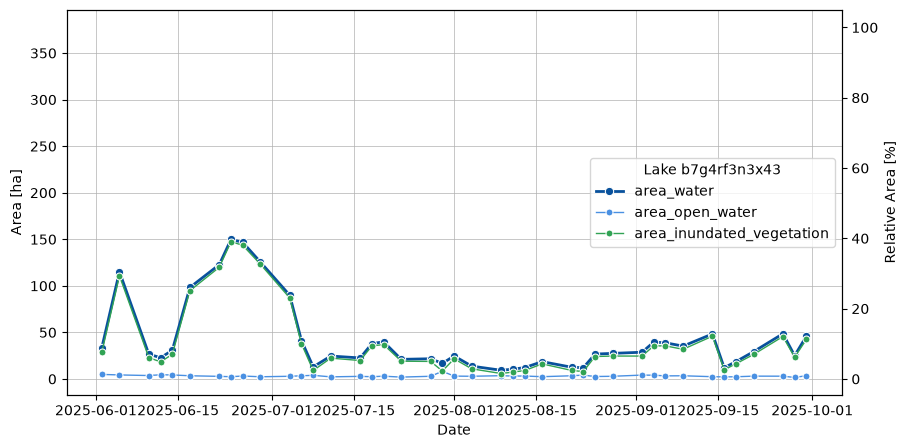

In [16]:
fig = dataset_daily.plot_timeseries(object_id=lake_id)


In [17]:
dataset_daily.plot_timeseries_interactive(object_id=lake_id)

#### Plot timeseries - monthly
* same API, monthly cadence
* `object_id=` is the current keyword; the older `id_geohash=` still works but emits a `FutureWarning`

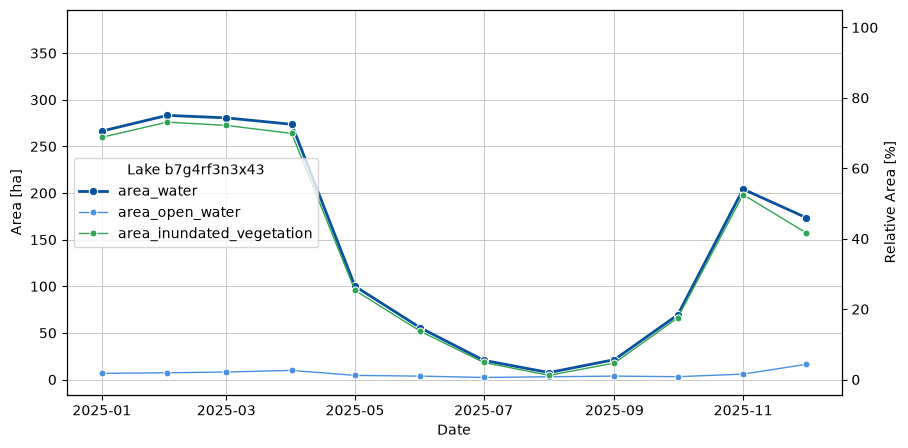

In [18]:
out_file = "lake_timeseries_dswx_monthly.png"
fig = dataset_monthly.plot_timeseries(object_id=lake_id, save_path=out_file)


In [19]:
out_file = "lake_timeseries_dswx_monthly.html"
dataset_monthly.plot_timeseries_interactive(object_id=lake_id, save_path=out_file)

#### Sanity check - the winter rows are ice, not water
The product has no snow/ice class, so a frozen basin is reported as *inundated vegetation*. Per-month medians make
that visible: `area_inundated_vegetation` is largest in winter and smallest in late summer, while `area_open_water`
moves far less. Any winter analysis therefore needs an ice gate from Dynamic World's `snow_and_ice` for the same
polygon and date - which is only possible on the per-acquisition product, because a monthly composite has already
mixed ice and open water.

In [20]:
monthly = (
    dataset_monthly.ds[["area_open_water", "area_inundated_vegetation", "area_water"]]
    .sel({dataset_monthly.id_field: lake_id})
    .to_dataframe()
)
monthly["month"] = monthly.index.month
cols = ["area_open_water", "area_inundated_vegetation", "area_water"]
monthly.groupby("month")[cols].median().round(2)

,area_open_water,area_inundated_vegetation,area_water
month,,,
1,6.63,259.76,266.39
2,7.26,275.99,283.25
3,8.07,272.51,280.58
4,9.78,263.91,273.68
5,4.47,95.58,100.05
6,3.66,51.79,55.45
7,2.25,18.35,20.60
8,2.97,4.50,7.47
9,3.69,17.65,21.34


#### Comparing with Dynamic World
* add DW's `flooded_vegetation` to its `water` before comparing - DSWx splits one water body into open water and
  inundated vegetation, and open water alone is roughly 63 % of DW's water
* expect DSWx to run a few percent below DW on a seasonal median (measured 3-11 % on two test lakes), which is the
  radar/optical and 30 m/10 m difference, not a bug
* to gate winter rows, pull DW per acquisition for the same days (`download_dw_daily`) and keep DSWx observations
  whose `snow_and_ice` share is below ~5 %